## 1. Import Libraries

The libraries below support data manipulation, visualization, preprocessing, model development, and evaluation.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

## 2. Load the Dataset

The CSV file is loaded into a Pandas DataFrame for analysis.

In [2]:
df = pd.read_csv("Kumasi_Traffic_Dataset.csv")

print(f"Dataset shape: {df.shape}")

Dataset shape: (1000, 15)


## 3. Initial Data Inspection

These checks establish the size, structure, data types, and basic statistical characteristics of the dataset.

In [3]:
df.head()

,record_id,road,location,day_of_week,time,time_period,is_weekend,vehicle_flow,vehicle_density,rainfall,road_condition,roadside_activity,traffic_signal,lane_reduction,traffic_level
0,1,Kumasi-Mampong Road,Suame,Sunday,14:00,Midday,1,214,22.4,0,Good,Low,No,No,Low
1,2,Kumasi-Offinso Road,Anloga Junction,Monday,12:30,Midday,0,361,28.7,0,Good,Medium,Yes,No,Low
2,3,Kumasi-Offinso Road,Offinso Junction,Sunday,19:30,Night,1,216,16.6,0,Poor,Medium,Yes,Yes,Low
3,4,Kumasi-Accra Road,Asokwa,Monday,16:45,Evening Peak,0,524,56.1,1,Good,Low,Yes,Yes,Medium
4,5,Kumasi-Mampong Road,Suame,Saturday,22:00,Night,1,295,34.1,0,Fair,Medium,Yes,No,Low


In [4]:
df.shape

(1000, 15)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   record_id          1000 non-null   int64  
 1   road               1000 non-null   str    
 2   location           1000 non-null   str    
 3   day_of_week        1000 non-null   str    
 4   time               1000 non-null   str    
 5   time_period        1000 non-null   str    
 6   is_weekend         1000 non-null   int64  
 7   vehicle_flow       1000 non-null   int64  
 8   vehicle_density    1000 non-null   float64
 9   rainfall           1000 non-null   int64  
 10  road_condition     1000 non-null   str    
 11  roadside_activity  1000 non-null   str    
 12  traffic_signal     1000 non-null   str    
 13  lane_reduction     1000 non-null   str    
 14  traffic_level      1000 non-null   str    
dtypes: float64(1), int64(4), str(10)
memory usage: 117.3 KB


In [6]:
df.describe()

,record_id,is_weekend,vehicle_flow,vehicle_density,rainfall
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.0000
mean,500.500000,0.26400,427.943000,41.471500,0.2610
std,288.819436,0.44102,136.890104,15.154634,0.4394
min,1.000000,0.00000,155.000000,11.800000,0.0000
25%,250.750000,0.00000,328.750000,30.675000,0.0000
50%,500.500000,0.00000,406.000000,38.500000,0.0000
75%,750.250000,1.00000,507.250000,50.050000,1.0000
max,1000.000000,1.00000,1075.000000,105.400000,1.0000


## 4. Data Quality Checks

Before modelling, we check for missing values and duplicate observations. Exact duplicates can give repeated observations unnecessary influence during training.

In [7]:
# Missing values
print("Missing values by column:")
print(df.isnull().sum())

# Exact duplicates
print("\nExact duplicate rows:", df.duplicated().sum())

# Duplicate traffic records excluding the unique identifier
print(
    "Duplicates excluding record_id:",
    df.drop(columns=["record_id"]).duplicated().sum()
)

Missing values by column:
record_id            0
road                 0
location             0
day_of_week          0
time                 0
time_period          0
is_weekend           0
vehicle_flow         0
vehicle_density      0
rainfall             0
road_condition       0
roadside_activity    0
traffic_signal       0
lane_reduction       0
traffic_level        0
dtype: int64

Exact duplicate rows: 0
Duplicates excluding record_id: 0


## 5. Exploratory Data Analysis

EDA is used to understand the distribution of congestion levels and examine how traffic conditions vary across roads, time periods, and vehicle flow.

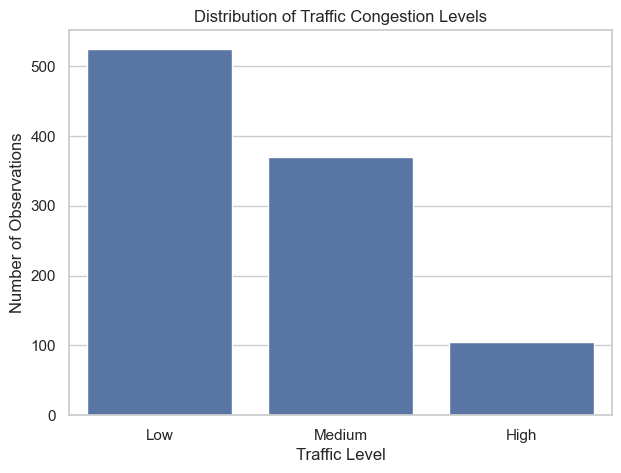

In [8]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x="traffic_level",
    order=["Low", "Medium", "High"]
)
plt.title("Distribution of Traffic Congestion Levels")
plt.xlabel("Traffic Level")
plt.ylabel("Number of Observations")
plt.show()

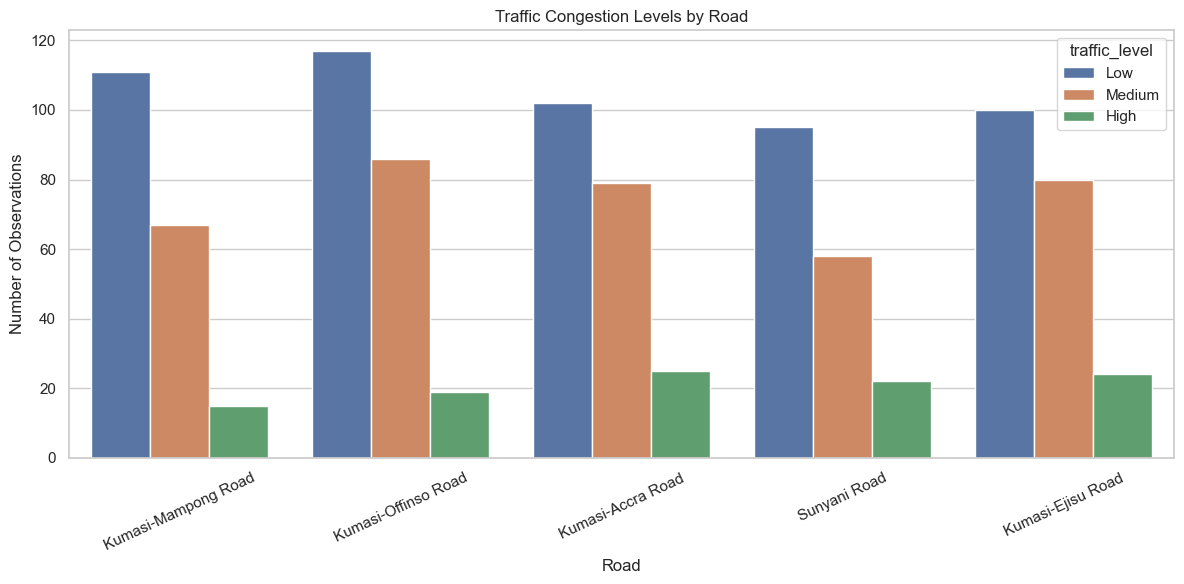

In [9]:
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df,
    x="road",
    hue="traffic_level"
)
plt.title("Traffic Congestion Levels by Road")
plt.xlabel("Road")
plt.ylabel("Number of Observations")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

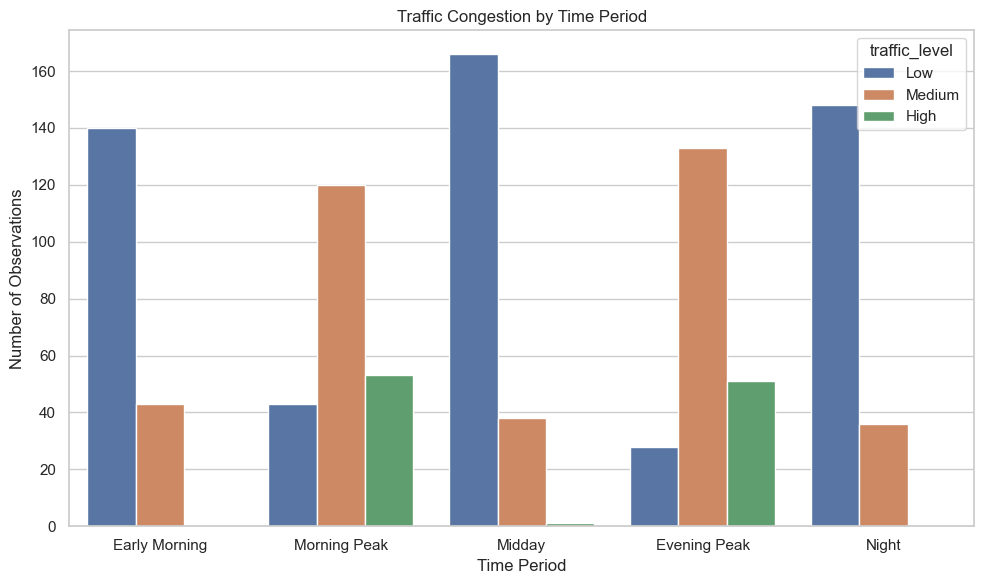

In [10]:
period_order = [
    "Early Morning",
    "Morning Peak",
    "Midday",
    "Evening Peak",
    "Night"
]

plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    x="time_period",
    hue="traffic_level",
    order=period_order
)
plt.title("Traffic Congestion by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

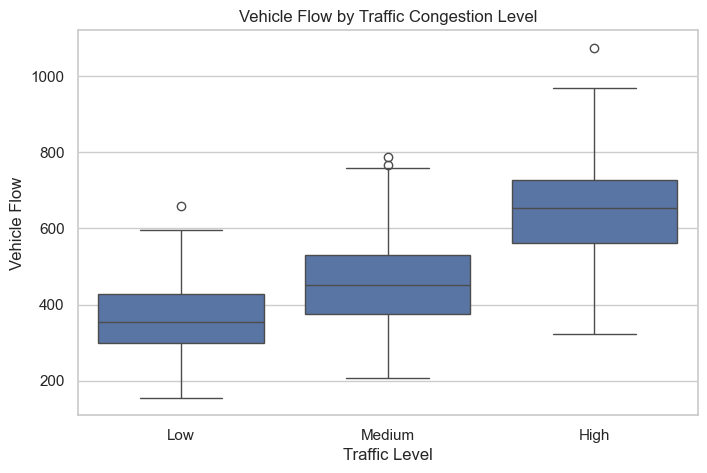

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="traffic_level",
    y="vehicle_flow",
    order=["Low", "Medium", "High"]
)
plt.title("Vehicle Flow by Traffic Congestion Level")
plt.xlabel("Traffic Level")
plt.ylabel("Vehicle Flow")
plt.show()

## 6. Define Features and Target

`X` contains the predictor variables, while `y` contains the traffic congestion class we want the model to predict. The record identifier is excluded because it has no predictive meaning.

In [12]:
target = "traffic_level"

X = df.drop(columns=[target, "record_id"])
y = df[target]

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['road', 'location', 'day_of_week', 'time', 'time_period', 'is_weekend', 'vehicle_flow', 'vehicle_density', 'rainfall', 'road_condition', 'roadside_activity', 'traffic_signal', 'lane_reduction']
Target: traffic_level


## 7. Identify Feature Types

Categorical and numerical variables require different preprocessing before they are passed to the classifiers.

In [13]:
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['road', 'location', 'day_of_week', 'time', 'time_period', 'road_condition', 'roadside_activity', 'traffic_signal', 'lane_reduction']
Numerical features: ['is_weekend', 'vehicle_flow', 'vehicle_density', 'rainfall']


C:\Users\Richard Kumi\AppData\Local\Temp\ipykernel_18812\2375927278.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns.tolist()


## 8. Train-Test Split

The data is divided into training and testing sets. The model learns from the training set and is evaluated on unseen test observations. Stratification helps preserve the class distribution.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 800
Testing observations: 200


## 9. Preprocessing Pipeline

Categorical variables are one-hot encoded, while numerical variables are standardized. Keeping preprocessing inside a pipeline also helps prevent inconsistent transformations between training and testing data.

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

## 10. Train Classification Models

Three classification approaches are tested: Logistic Regression, Decision Tree, and Random Forest. Using several models allows us to compare their performance on the same problem.

In [19]:
# Logistic Regression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Generate predictions on the test set
logistic_predictions = logistic_model.predict(X_test)

# Evaluate the model
logistic_accuracy = accuracy_score(y_test, logistic_predictions)

print("=" * 60)
print("LOGISTIC REGRESSION")
print("=" * 60)

print(f"Test Accuracy: {logistic_accuracy:.4f} ({logistic_accuracy * 100:.2f}%)")

print("\nClassification Report:")
print(classification_report(y_test, logistic_predictions, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions))

LOGISTIC REGRESSION
Test Accuracy: 0.7950 (79.50%)

Classification Report:
              precision    recall  f1-score   support

        High       0.76      0.62      0.68        21
         Low       0.83      0.91      0.87       105
      Medium       0.75      0.68      0.71        74

    accuracy                           0.80       200
   macro avg       0.78      0.74      0.75       200
weighted avg       0.79      0.80      0.79       200

Confusion Matrix:
[[13  0  8]
 [ 0 96  9]
 [ 4 20 50]]


In [20]:
# Decision Tree
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=42,
        max_depth=6
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

# Generate predictions
decision_tree_predictions = decision_tree_model.predict(X_test)

# Evaluate the model
decision_tree_accuracy = accuracy_score(
    y_test,
    decision_tree_predictions
)

print("=" * 60)
print("DECISION TREE")
print("=" * 60)

print(
    f"Test Accuracy: {decision_tree_accuracy:.4f} "
    f"({decision_tree_accuracy * 100:.2f}%)"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        decision_tree_predictions,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        decision_tree_predictions
    )
)

DECISION TREE
Test Accuracy: 0.7650 (76.50%)

Classification Report:
              precision    recall  f1-score   support

        High       0.65      0.52      0.58        21
         Low       0.81      0.92      0.86       105
      Medium       0.71      0.61      0.66        74

    accuracy                           0.77       200
   macro avg       0.72      0.69      0.70       200
weighted avg       0.76      0.77      0.76       200

Confusion Matrix:
[[11  0 10]
 [ 0 97  8]
 [ 6 23 45]]


In [21]:
# Random Forest
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        max_depth=10
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Generate predictions
random_forest_predictions = random_forest_model.predict(X_test)

# Evaluate the model
random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_predictions
)

print("=" * 60)
print("RANDOM FOREST")
print("=" * 60)

print(
    f"Test Accuracy: {random_forest_accuracy:.4f} "
    f"({random_forest_accuracy * 100:.2f}%)"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        random_forest_predictions,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        random_forest_predictions
    )
)

RANDOM FOREST
Test Accuracy: 0.7900 (79.00%)

Classification Report:
              precision    recall  f1-score   support

        High       0.90      0.43      0.58        21
         Low       0.83      0.91      0.87       105
      Medium       0.72      0.72      0.72        74

    accuracy                           0.79       200
   macro avg       0.81      0.69      0.72       200
weighted avg       0.79      0.79      0.78       200

Confusion Matrix:
[[ 9  0 12]
 [ 0 96  9]
 [ 1 20 53]]


## 11. Compare Model Accuracy

Accuracy measures the proportion of test observations classified correctly. It provides an initial comparison, but we will also examine class-level metrics because the dataset is not perfectly balanced.

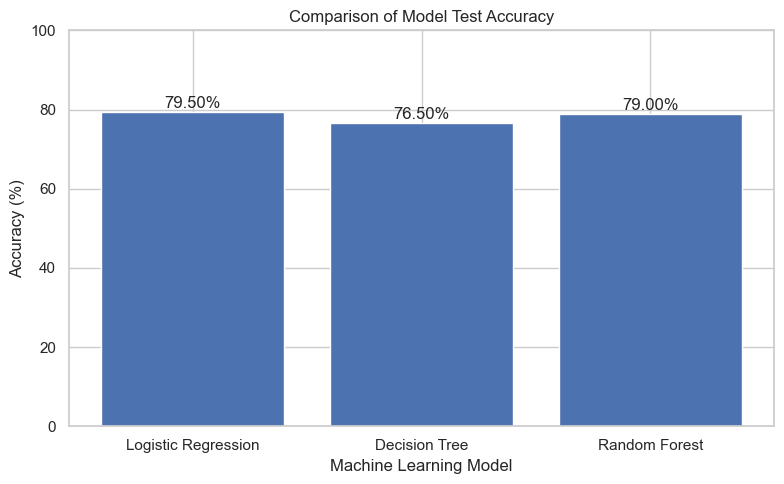

In [23]:
# Visual comparison of model accuracy

plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["Accuracy"] * 100
)

plt.title("Comparison of Model Test Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(results["Accuracy"] * 100):
    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

## 12. Detailed Model Evaluation

Precision, recall, and F1-score provide a more detailed view of how each model handles Low, Medium, and High congestion.

In [24]:
models_and_predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions
}

for model_name, predictions in models_and_predictions.items():
    print("=" * 65)
    print(model_name)
    print("=" * 65)
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

Logistic Regression
              precision    recall  f1-score   support

        High       0.76      0.62      0.68        21
         Low       0.83      0.91      0.87       105
      Medium       0.75      0.68      0.71        74

    accuracy                           0.80       200
   macro avg       0.78      0.74      0.75       200
weighted avg       0.79      0.80      0.79       200

Decision Tree
              precision    recall  f1-score   support

        High       0.65      0.52      0.58        21
         Low       0.81      0.92      0.86       105
      Medium       0.71      0.61      0.66        74

    accuracy                           0.77       200
   macro avg       0.72      0.69      0.70       200
weighted avg       0.76      0.77      0.76       200

Random Forest
              precision    recall  f1-score   support

        High       0.90      0.43      0.58        21
         Low       0.83      0.91      0.87       105
      Medium       0.72    

## 13. Confusion Matrix

The confusion matrix shows which traffic classes are correctly classified and where the model confuses one class with another.

Model with highest test accuracy: Logistic Regression


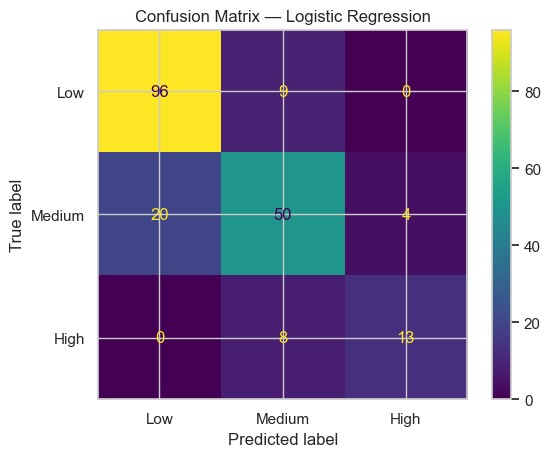

In [25]:
accuracy_lookup = {
    "Logistic Regression": accuracy_score(y_test, logistic_predictions),
    "Decision Tree": accuracy_score(y_test, decision_tree_predictions),
    "Random Forest": accuracy_score(y_test, random_forest_predictions)
}

best_model_name = max(accuracy_lookup, key=accuracy_lookup.get)
best_predictions = models_and_predictions[best_model_name]

print("Model with highest test accuracy:", best_model_name)

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["Low", "Medium", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

disp.plot()
plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

## 14. Model Comparison

The table below provides the final test-set accuracy comparison used in this initial experiment.

In [26]:
display(
    results.sort_values(
        "Accuracy",
        ascending=False
    ).reset_index(drop=True)
)

print(
    f"\nHighest test accuracy: "
    f"{best_model_name} "
    f"({accuracy_lookup[best_model_name]:.4f})"
)

,Model,Accuracy
0,Logistic Regression,0.795
1,Random Forest,0.790
2,Decision Tree,0.765



Highest test accuracy: Logistic Regression (0.7950)


## 15. Example Traffic Prediction

A hypothetical new traffic observation is passed through the selected model to demonstrate how the finished classifier can be used.

In [27]:
new_traffic = pd.DataFrame([{
    "road": "Kumasi-Accra Road",
    "location": "Asokwa",
    "day_of_week": "Monday",
    "time": "07:30",
    "time_period": "Morning Peak",
    "is_weekend": 0,
    "vehicle_flow": 750,
    "vehicle_density": 70.0,
    "rainfall": 1,
    "road_condition": "Fair",
    "roadside_activity": "High",
    "traffic_signal": "Yes",
    "lane_reduction": "No"
}])

if best_model_name == "Logistic Regression":
    prediction = logistic_model.predict(new_traffic)[0]
elif best_model_name == "Decision Tree":
    prediction = decision_tree_model.predict(new_traffic)[0]
else:
    prediction = random_forest_model.predict(new_traffic)[0]

print("Predicted traffic level:", prediction)

Predicted traffic level: High
